# Importing Modules

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import LSTM, Dense, Embedding, Input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
import numpy as np

# Data Cleaning

In [3]:
with open('corpus.txt', 'r') as file:
  data = file.read()
texts = data.split('\n')

In [4]:
texts[:10]

['they make some cold water late at night',
 'the dog sees a new book late at night',
 'my father eats a small gift before dinner',
 'my father runs happily at home after lunch',
 'there is a quiet city at school',
 'the dark city is at school',
 'there is a beautiful market near the river',
 'the clean shop is in the garden',
 'my father makes the red car near the river',
 'they see some cold water at school']

In [5]:
texts.pop()

''

In [6]:
no_of_text = len(texts)
no_of_text

5827

# Data Tokenization

In [7]:
tokenizer = Tokenizer()

In [8]:
tokenizer.fit_on_texts(texts)

In [9]:
no_of_words = len(tokenizer.word_index)
no_of_words

478

In [10]:
tokenized_texts = []
for text in texts:
  tokenized_texts.append(tokenizer.texts_to_sequences([text])[0])
tokenized_texts[:10]

[[67, 127, 17, 32, 60, 39, 4, 36],
 [1, 86, 70, 3, 22, 53, 39, 4, 36],
 [7, 74, 72, 3, 25, 50, 34, 35],
 [7, 74, 117, 99, 4, 27, 43, 44],
 [8, 5, 3, 109, 12, 4, 14],
 [1, 104, 12, 5, 4, 14],
 [8, 5, 3, 107, 15, 18, 1, 13],
 [1, 111, 102, 5, 2, 1, 11],
 [7, 74, 88, 1, 58, 62, 18, 1, 13],
 [67, 115, 17, 32, 60, 4, 14]]

# Input Label Formatting

In [11]:
text_sequences = []
for text in tokenized_texts:
  for i in range(1, len(text)):
    text_sequences.append(text[:i+1])

text_sequences[:20]

[[67, 127],
 [67, 127, 17],
 [67, 127, 17, 32],
 [67, 127, 17, 32, 60],
 [67, 127, 17, 32, 60, 39],
 [67, 127, 17, 32, 60, 39, 4],
 [67, 127, 17, 32, 60, 39, 4, 36],
 [1, 86],
 [1, 86, 70],
 [1, 86, 70, 3],
 [1, 86, 70, 3, 22],
 [1, 86, 70, 3, 22, 53],
 [1, 86, 70, 3, 22, 53, 39],
 [1, 86, 70, 3, 22, 53, 39, 4],
 [1, 86, 70, 3, 22, 53, 39, 4, 36],
 [7, 74],
 [7, 74, 72],
 [7, 74, 72, 3],
 [7, 74, 72, 3, 25],
 [7, 74, 72, 3, 25, 50]]

In [12]:
max_length = max(len(x) for x in text_sequences)
max_length

14

In [13]:
text_sequences = pad_sequences(text_sequences, maxlen=max_length, padding='pre')

In [15]:
text_sequences[:10]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  67,
        127],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  67, 127,
         17],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  67, 127,  17,
         32],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  67, 127,  17,  32,
         60],
       [  0,   0,   0,   0,   0,   0,   0,   0,  67, 127,  17,  32,  60,
         39],
       [  0,   0,   0,   0,   0,   0,   0,  67, 127,  17,  32,  60,  39,
          4],
       [  0,   0,   0,   0,   0,   0,  67, 127,  17,  32,  60,  39,   4,
         36],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
         86],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,  86,
         70],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,  86,  70,
          3]], dtype=int32)

In [16]:
input_sequences = text_sequences[:, :-1]

In [17]:
label = text_sequences[:, -1]

In [18]:
label = to_categorical(label, num_classes=no_of_words+1)

In [19]:
(no_of_data, label_length) = label.shape

# Model building and training

In [20]:
model = Sequential()
Input(shape=(max_length-1,))
model.add(Embedding(no_of_words+1, 150))
model.add(LSTM(256))
model.add(Dense(no_of_words+1, activation='sigmoid'))
model.add(Dense(no_of_words+1, activation='softmax'))

In [21]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [22]:
history = model.fit(input_sequences, label, epochs=100)

Epoch 1/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.3761 - loss: 2.3443
Epoch 2/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.4650 - loss: 1.5405
Epoch 3/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4718 - loss: 1.4401
Epoch 4/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4840 - loss: 1.3651
Epoch 5/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.4981 - loss: 1.3105
Epoch 6/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.5090 - loss: 1.2729
Epoch 7/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.5136 - loss: 1.2537
Epoch 8/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.5155 - loss: 1.2408
Epoch 9/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.5188 - loss: 1.2327
Epoch 10/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.5190 - loss: 1.2278
Epoch 11/100
1417/1417 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.5209 - loss: 1.2239
Epoch 12/100
1417

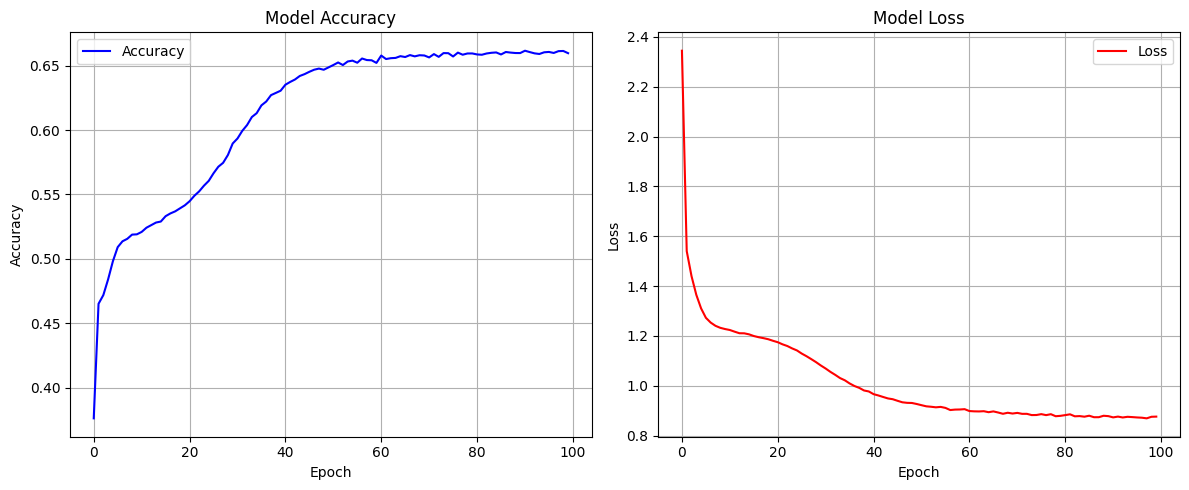

In [23]:
import matplotlib.pyplot as plt

# Plot training accuracy & loss
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy', color='blue')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss', color='red')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 13, 150)        │        71,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       416,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 479)            │       123,103 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 479)            │       229,920 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,524,925 (9.63 MB)

 Trainable params: 841,641 (3.21 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,683,284 (6.42 MB)

# Testing using argmax

In [25]:
test = 'market'
test1 = pad_sequences(tokenizer.texts_to_sequences([test]), maxlen=max_length-1, padding='pre')
pos = np.argmax(model.predict(test1))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step


In [26]:
for word, index in tokenizer.word_index.items():
  if index == pos:
    print(word)

is


In [27]:
test = 'cat'
for i in range(10):
  test1 = pad_sequences(tokenizer.texts_to_sequences([test]), maxlen=max_length-1, padding='pre')
  pos = np.argmax(model.predict(test1)[0])
  for word, index in tokenizer.word_index.items():
    if index == pos:
      #print(word)
      test = test + ' ' + word

print(test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
cat teacher takes some fresh bread after lunch i walk big


In [28]:
test = 'they'
for i in range(10):
  test1 = pad_sequences(tokenizer.texts_to_sequences([test]), maxlen=max_length-1, padding='pre')
  pos = np.argmax(model.predict(test1)[0])
  for word, index in tokenizer.word_index.items():
    if index == pos:
      #print(word)
      test = test + ' ' + word

print(test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
they bring the old house in the garden after lunch the


# Testing using temperature

In [29]:
def sample_with_temperature(preds, temperature=1.0):
    # Helper function to sample an index from a probability array
    preds = np.asarray(preds).astype('float64')
    if temperature <= 0:
        return np.argmax(preds)

    # Apply temperature scaling to the probabilities
    preds = np.maximum(preds, 1e-10)
    preds = preds ** (1/temperature)
    preds = preds / np.sum(preds)

    # Draw a sample from the multinomial distribution
    probas = np.random.multinomial(1, preds, 1)
    return np.argmax(probas)

In [48]:
temp = 0.7
test = 'cat'
for i in range(7):
  test1 = pad_sequences(tokenizer.texts_to_sequences([test]), maxlen=max_length-1, padding='pre')
  pos = sample_with_temperature(model.predict(test1)[0], temperature=temp)
  for word, index in tokenizer.word_index.items():
    if index == pos:
      #print(word)
      test = test + ' ' + word

print(test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
cat carries the green apple before dinner you


In [30]:
temp = 0.7
test = 'they'
for i in range(7):
  test1 = pad_sequences(tokenizer.texts_to_sequences([test]), maxlen=max_length-1, padding='pre')
  pos = sample_with_temperature(model.predict(test1)[0], temperature=temp)
  for word, index in tokenizer.word_index.items():
    if index == pos:
      #print(word)
      test = test + ' ' + word

print(test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
they built a small house near the lake


# Saving model

In [ ]:
model.save('text_generation_model.keras')
print('Model saved successfully as text_generation_model.keras')